### TEL354 - Minería de datos
# Clase 8: Discriminative Classifiers
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
from Clase8 import *

In [2]:
plt.rc('figure', figsize=(8, 6))

# Clasificación

Predice la clase o categoría a la que pertenece una observación, basándose en sus características o atributos. En esencia, es un problema de asignar una etiqueta a una entrada, de acuerdo con un conjunto de ejemplos de entrenamiento previamente etiquetados.

<div align="center">
    <img src="img/supervised-machine-learning.png" alt="" width="50%" align="center" />
</div>

## Regresión vs Clasificación

### Regresión

- salida numérica
- predice valores continuos
- Ejemplo: precio casa 

### Clasificación

- salida categórica
- predice etiquetas
- Ejemplo: spam / no spam

## Modelos discriminativos

Modelan directamente la frontera de decisión que separa las diferentes clases en el espacio de características. Es decir, se enfoca en aprender la relación entre las características de entrada (variables predictoras) y las clases de salida (etiquetas). Ejemplos de modelos discriminativos: Máquinas de Soporte Vectorial (SVM) y Regresión Logística.

<div align="center">
    <img src="img/disc_gen.png" alt="" width="50%" align="center" />
</div>

### Frontera de decisión

La frontera de decisión es la línea, curva o hiperplano que separa las diferentes clases en un problema de clasificación.

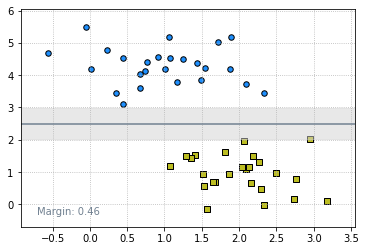

In [64]:
recta = (0, 2.5)
discriminative(boundary = recta)

# Máquinas de Soporte Vectorial (SVM)

SVM es un modelo discriminativo que busca el hiperplano que maximiza el margen entre las clases, definido como la distancia perpendicular desde el hiperplano de separación a las observaciones de entrenamiento más cercanas de cada clase, también llamadas vectores de soporte.

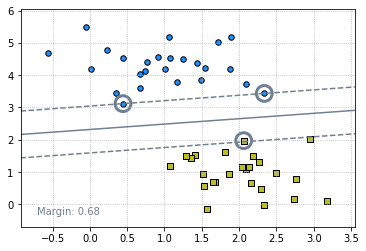

In [69]:
discriminative(svm = True, show_vectors = True, C=1)

## Variables de holgura

Las variables de holgura o "slack variables" son especialmente útiles para manejar datos que no son linealmente separables, ya que permiten flexibilidad de la frontera de decisión, aceptando errores de clasificación en los datos de entrenamiento. Sin embargo, pueden introducir sobreajuste.

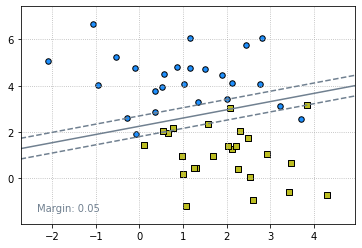

In [74]:
discriminative(cluster_std=1.2, svm = True, show_vectors=False, C=100)

# El caso no separable

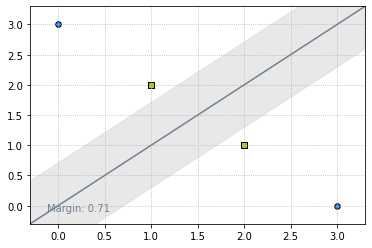

In [6]:
discriminative(data=([[0,3],[1,2],[2,1],[3,0]], [0,1,1,0]), boundary=(1,0))

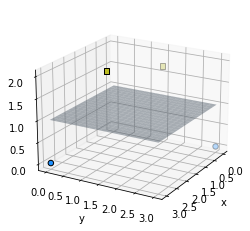

In [7]:
discriminative(data=([[0,3],[1,2],[2,1],[3,0]], [0,1,1,0]), boundary=1, z=[0,2,2,0])

# Kernel Trick

Cuando nuestro problema no es linealmente separable, necesitamos aplicar una transformación en nuestra matriz de atributos para reexpresarlos en un nuevo espacio. El uso del "Kernel Trick" permite que las SVM puedan modelar relaciones no lineales, ya que pueden encontrar fronteras de decisión más complejas en un espacio de características de mayor dimensión. 

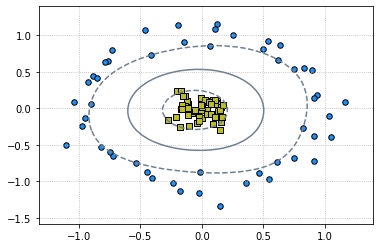

In [75]:
discriminative(data='circles', n_samples=100, z=False, svm=True, kernel='rbf')

# Clasificación multiclase usando SVM

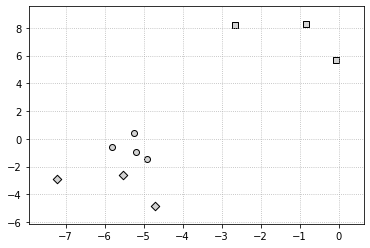

In [9]:
multiclass_svm()

# One vs Rest (OvR)
Se entrena un clasificador binario para cada clase, donde esa clase se trata como positiva y todas las demás clases se agrupan como negativa. Luego, durante la clasificación, se elige la clase que tenga la mayor puntuación de confianza entre todos los clasificadores binarios como la clase predicha para la instancia.

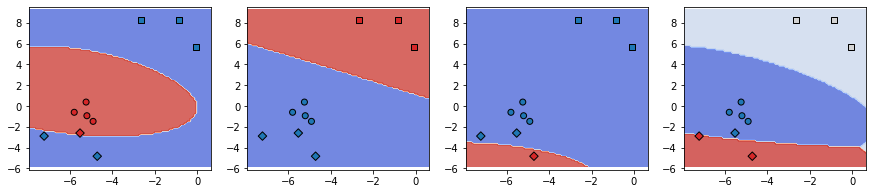

In [10]:
multiclass_svm(method='ovr')

# One vs One (OvO)

Se entrena un clasificador binario para cada par de clases que distingue entre esas dos clases específicas. Durante la clasificación, se realiza una votación entre todos los clasificadores binarios y la clase que obtiene la mayoría de los votos se elige como la clase predicha para la instancia.

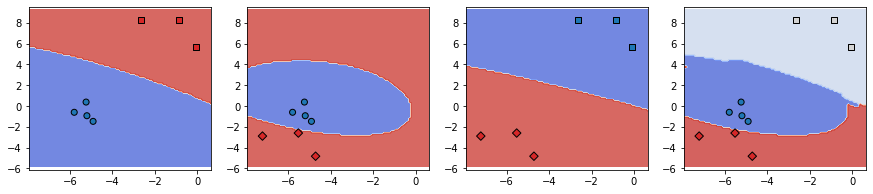

In [11]:
multiclass_svm(method='ovo')

## Face Recognition

In [12]:
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
(1348, 62, 47)


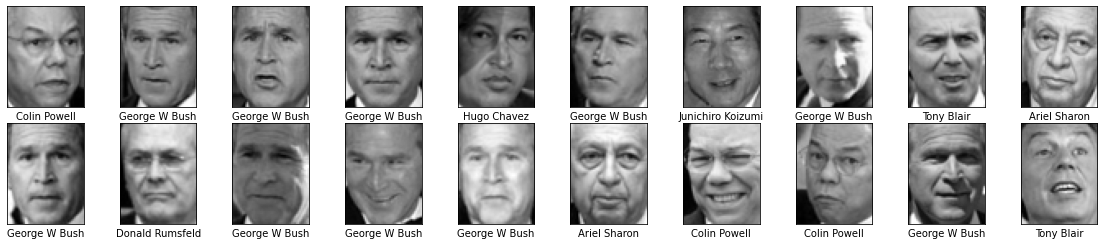

In [13]:
plot_faces(faces, n_rows=2, n_cols=10)

In [14]:
pca = PCA(n_components=150, whiten=True, svd_solver='randomized', random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(pca, svc)
X_train, X_test, y_train, y_test = train_test_split(faces.data, faces.target, random_state=42)

In [15]:
param_grid = {'svc__C': [1, 5, 10, 50], 'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid).fit(X_train, y_train)
print(grid.best_params_)
model = grid.best_estimator_
y_pred = model.predict(X_test)

{'svc__C': 5, 'svc__gamma': 0.001}


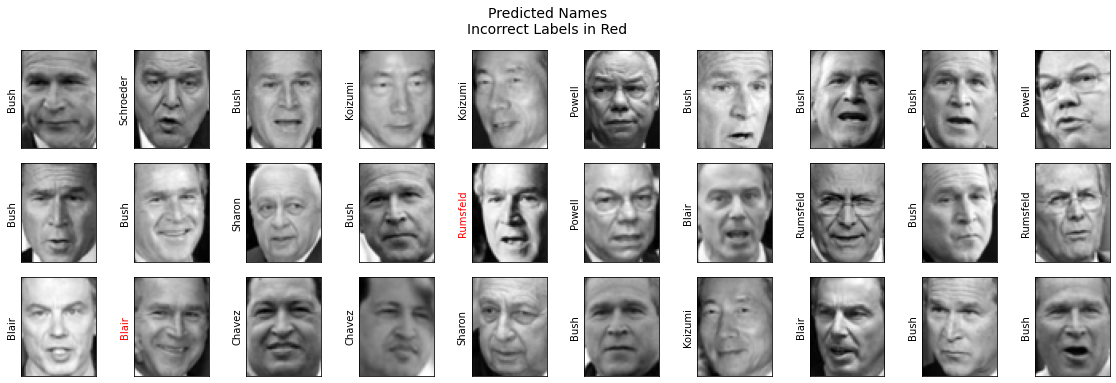

In [16]:
plot_faces(faces, 3, 10, X_test, y_pred, y_test, 'Predicted Names\nIncorrect Labels in Red')

# Métricas de clasificación

Las métricas de clasificación son herramientas utilizadas para evaluar el rendimiento de un modelo de clasificación sobre un conjunto de datos.

- **Precision**: Proporción de instancias clasificadas como positivas que son realmente positivas. 

- **Recall**: Proporción de instancias positivas que fueron correctamente clasificadas por el modelo. 

- **F1-score**: Media armónica de la precisión y el recall: $F1 = 2 \cdot \frac{\mathbf{precision} \cdot \mathbf{recall}}{\mathbf{precision} + \mathbf{recall}}$

- **Accuracy**: Proporción de instancias correctamente clasificadas por el modelo, independientemente de su clase. 

## ¿Cuándo usar cada métrica?

**Accuracy:** cuando clases están balanceadas

**Precision:** cuando los falsos positivos son costosos  (ej: spam)

**Recall:** cuando los falsos negativos son críticos  (ej: enfermedades)

**F1-score:** equilibrio entre precision y recall

In [17]:
print(classification_report(y_test, y_pred,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



# Matriz de confusión

Permite visualizar el desempeño de un algoritmo en aprendizaje supervisado. Cada columna representa el número de predicciones de cada clase, mientras que cada fila representa a las instancias en la clase real.

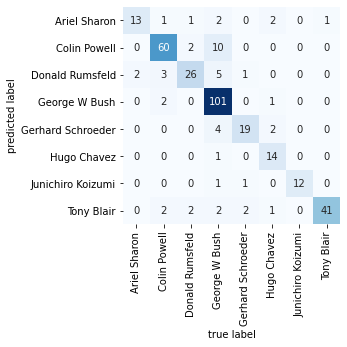

In [18]:
plot_confusion_matrix(faces, y_test, y_pred)